In [1]:
import os
import warnings
from pathlib import Path
from sklearn.utils import compute_sample_weight
import shap


import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import yaml

from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.datasets import make_classification
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import compute_sample_weight, shuffle
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

/opt/anaconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_data(path):
    files = os.listdir(path)
    df = pd.read_csv(os.path.join(path, files[0]))
    return df
df = load_data("/Users/enkhjin/.cache/kagglehub/datasets/saurabhbadole/bank-customer-churn-prediction-dataset/versions/2")
print(df.describe())  

         RowNumber    CustomerId   CreditScore           Age        Tenure  \
count  10000.00000  1.000000e+04  10000.000000  10000.000000  10000.000000   
mean    5000.50000  1.569094e+07    650.528800     38.921800      5.012800   
std     2886.89568  7.193619e+04     96.653299     10.487806      2.892174   
min        1.00000  1.556570e+07    350.000000     18.000000      0.000000   
25%     2500.75000  1.562853e+07    584.000000     32.000000      3.000000   
50%     5000.50000  1.569074e+07    652.000000     37.000000      5.000000   
75%     7500.25000  1.575323e+07    718.000000     44.000000      7.000000   
max    10000.00000  1.581569e+07    850.000000     92.000000     10.000000   

             Balance  NumOfProducts    HasCrCard  IsActiveMember  \
count   10000.000000   10000.000000  10000.00000    10000.000000   
mean    76485.889288       1.530200      0.70550        0.515100   
std     62397.405202       0.581654      0.45584        0.499797   
min         0.000000     

In [3]:
def load_config(path=None):
    if path is not None:
        config_path = Path(path)
        if not config_path.is_file():
            raise FileNotFoundError(f"Configuration file not found: {config_path}")
    else:
        config_candidates = (
            Path("configs.yaml"),
            Path("../configs.yaml"),
            Path("config/configs.yaml"),
            Path("../config/configs.yaml"),
        )
        config_path = next((candidate for candidate in config_candidates if candidate.is_file()), None)
        if config_path is None:
            searched = ", ".join(str(candidate) for candidate in config_candidates)
            raise FileNotFoundError(f"Could not find configs.yaml; searched: {searched}")

    with config_path.open("r", encoding="utf-8") as config_file:
        return yaml.safe_load(config_file)
if __name__ == "main":
    config = load_config()
    print(config)

In [4]:
def check_missing_duplicated_values(df):
    if df.empty:
        print("The DataFrame is empty.")
        return None, None
    missing_values = df.isnull().any()
    duplicated_rows = df.duplicated().any()
    check = missing_values.sum() or duplicated_rows.sum()
    if missing_values.sum() > 0:
        print("There are missing values in the DataFrame.")
    if duplicated_rows.sum() > 0:
        print("There are duplicated rows in the DataFrame.")
    return check
if __name__ == "__main__":
    print(check_missing_duplicated_values(df))
    

0


In [5]:
def number_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return 0
    numeric_columns = df.select_dtypes(include=['number']).shape[1]
    return numeric_columns
if __name__ == "__main__":
    print("Number of numeric columns:", number_columns(df))

Number of numeric columns: 11


In [6]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [7]:
('line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin')

('line',
 'bar',
 'barh',
 'kde',
 'density',
 'area',
 'hist',
 'box',
 'pie',
 'scatter',
 'hexbin')

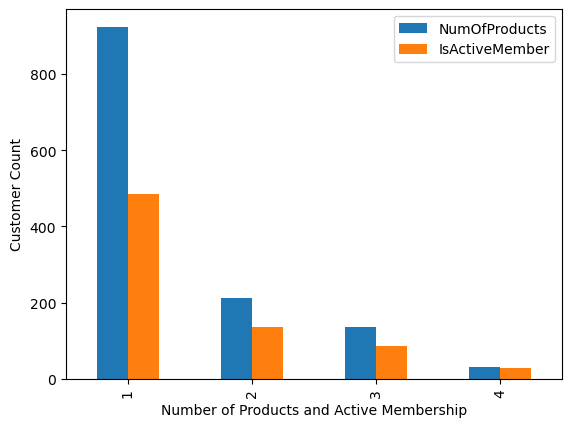

In [8]:
exited = df[df['Exited'] == 1]
value_counts = pd.crosstab(
    exited['NumOfProducts'], exited['IsActiveMember']
)

value_counts.plot(kind='bar')
plt.xlabel('Number of Products and Active Membership')
plt.ylabel('Customer Count')
plt.legend(['NumOfProducts', 'IsActiveMember'])
plt.show()

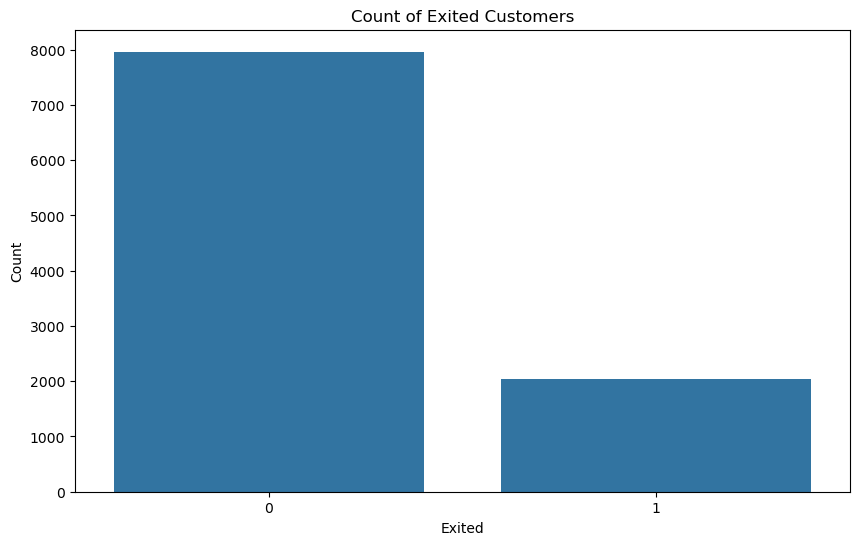

None


In [9]:
def plot(df):
    plt.figure(figsize=(10, 6))
    sns.countplot(x='Exited', data=df)
    plt.title('Count of Exited Customers')
    plt.xlabel('Exited')
    plt.ylabel('Count')
    plt.show()
if __name__ == "__main__":
    print(plot(df))


 We plotted the exited costumers to check the class imbalance, and adjust later on our upsampling strategy. 

In [10]:

print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [11]:
def drop_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return df
    return df.drop(columns=['Surname', 'RowNumber', 'CustomerId'])

df_drop = drop_columns(df)
print(df_drop.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [12]:
def splitting_raw_data(df_drop):
    if df_drop.empty:
        print("The DataFrame is empty.")
        return None, None, None, None
    X = df_drop.drop(columns=['Exited'])
    y = df_drop['Exited']
    x_temp, x_test, y_temp, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)
    return x_train, x_val, x_test, y_train, y_val, y_test
x_train_raw, x_val_raw, x_test, y_train_raw, y_val_raw, y_test = splitting_raw_data(df_drop)
print(x_train_raw.shape, x_val_raw.shape, x_test.shape, y_train_raw.shape, y_val_raw.shape, y_test.shape)

(5625, 10) (1875, 10) (2500, 10) (5625,) (1875,) (2500,)


In [13]:

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 
         Pipeline([
             ('imp', SimpleImputer(strategy='median')), 
             ('scl', StandardScaler())]), selector(dtype_include=np.number)),
        ('cat', 
         Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')),
                   ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
                   ]), 
         selector(dtype_include=object))])
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_raw
)

param_grid ={
    
    "Logistic Regression": {
        'classifier': [LogisticRegression(solver='liblinear', random_state=42
                                        #   , class_weight='balanced'
                                          )],
        'classifier__C': [0.01, 0.1, 1.0, 10.0],
        'classifier__penalty': ['l1', 'l2'], 
        'classifier__max_iter': [150, 200, 300]
    },
    "Random Forest":{
        'classifier': [RandomForestClassifier(random_state=42)],
        'classifier__n_estimators': [50, 100, 200],
        'classifier__max_depth': [5, 10, None],
        # 'classifier__class_weight': ['balanced', 'balanced_subsample']
        },
    "Gradient Boosting": {
        'classifier': [GradientBoostingClassifier(loss='log_loss', random_state=42) ],
        'classifier__n_estimators': [50, 100],
        'classifier__learning_rate': [0.05, 0.1, 0.2],
        'classifier__max_depth': [3, 5, 7]
        }}
full_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear', random_state=42))])  #])
searches = {}
results = []
for name,grid in param_grid.items():
    search = GridSearchCV(
        estimator=full_pipeline,
        param_grid=grid, 
        cv=3,
        scoring='f1',
        n_jobs=-1,
        refit=True)
    search.fit(x_train_raw, y_train_raw, classifier__sample_weight=sample_weights )
    prediction = search.predict(x_val_raw)
    searches[name] = search
    probability = search.predict_proba(x_val_raw)[:, 1]
    f1 = f1_score(y_val_raw, prediction)
    # recall = recall_score(y_val, prediction)
    results.append({
        "Model": name,
        "Validation F1": f1_score(y_val_raw, prediction),
        "Accuracy": accuracy_score(y_val_raw, prediction),
        "Precision": precision_score(y_val_raw, prediction),
        "Recall": recall_score(y_val_raw, prediction),
        "ROC AUC": roc_auc_score(y_val_raw, probability)})

# Create results DataFrame
results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(3))

# Select the model with the highest F1
best_name = results_df["Validation F1"].idxmax()

# Retrieve its fitted GridSearchCV object
best_search = searches[best_name]

# Retrieve the optimized pipeline
best_model = best_search.best_estimator_

# Make predictions using the actual winning model
best_prediction = best_model.predict(x_val_raw)
best_probability = best_model.predict_proba(x_val_raw)[:, 1]

# Evaluate the winning model
print(f"\nWinning Model: {best_name}")
print(f"Best Parameters: {best_search.best_params_}")
print(f"Best Validation F1: {best_search.best_score_:.2%}")

print("\nWinning Model Validation Results:")
print(f"Validation F1: {f1_score(y_val_raw, best_prediction):.2%}")
print(f"Accuracy: {accuracy_score(y_val_raw, best_prediction):.2%}")
print(f"Precision: {precision_score(y_val_raw, best_prediction):.2%}")
print(f"Recall: {recall_score(y_val_raw, best_prediction):.2%}")
print(f"ROC AUC: {roc_auc_score(y_val_raw, best_probability):.2%}")

,Validation F1,Accuracy,Precision,Recall,ROC AUC
Model,,,,,
Logistic Regression,0.471,0.686,0.359,0.686,0.755
Random Forest,0.588,0.787,0.485,0.746,0.846
Gradient Boosting,0.608,0.802,0.510,0.754,0.861



Winning Model: Gradient Boosting
Best Parameters: {'classifier': GradientBoostingClassifier(random_state=42), 'classifier__learning_rate': 0.2, 'classifier__max_depth': 3, 'classifier__n_estimators': 50}
Best Validation F1: 59.37%

Winning Model Validation Results:
Validation F1: 60.82%
Accuracy: 80.21%
Precision: 50.97%
Recall: 75.39%
ROC AUC: 86.11%


In [ ]:
# def encoding_columns(df):
#     if df.empty:
#         print("The DataFrame is empty.")
#         return df
#     categorical_columns = df.select_dtypes(include=['object']).columns
#     print("Categorical columns to encode:", categorical_columns)
#     df_encoded = pd.get_dummies(df, drop_first=True,
#                                 columns = categorical_columns,
#                                 dtype=int)
#     return df_encoded
# df_encoded = encoding_columns(df_drop)
# print(df_encoded.head())

Categorical columns to encode: Index(['Geography', 'Gender'], dtype='object')
   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0               1        101348.88       1                  0   
1               1        112542.58       0                  0   
2               0        113931.57       1                  0   
3               0         93826.63       0                  0   
4               1         79084.10       0                  0   

   Geography_Spain  Gender_Male  
0                0            0  
1                1            0  
2                0  

In [ ]:
# df_encoded.head()
# df_exited = df_encoded[df_encoded['Exited'] == 1]
# df_exited.value_counts()

CreditScore  Age  Tenure  Balance    NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  Geography_Germany  Geography_Spain  Gender_Male
350          39   0       109733.20  2              0          0               123602.11        1       1                  0                1              1
             40   0       111098.85  1              1          1               172321.21        1       0                  0                0              1
             51   10      0.00       1              1          1               125823.79        1       0                  0                1              1
             54   1       152677.48  1              1          1               191973.49        1       0                  1                1              1
             60   3       0.00       1              0          0               113796.15        1       0                  0                0              1
                                                               

Age                  0.285323
Geography_Germany    0.173488
Balance              0.118533
EstimatedSalary      0.012097
HasCrCard           -0.007138
Tenure              -0.014001
CreditScore         -0.027094
NumOfProducts       -0.047820
Geography_Spain     -0.052667
Gender_Male         -0.106512
IsActiveMember      -0.156128
Name: Exited, dtype: float64


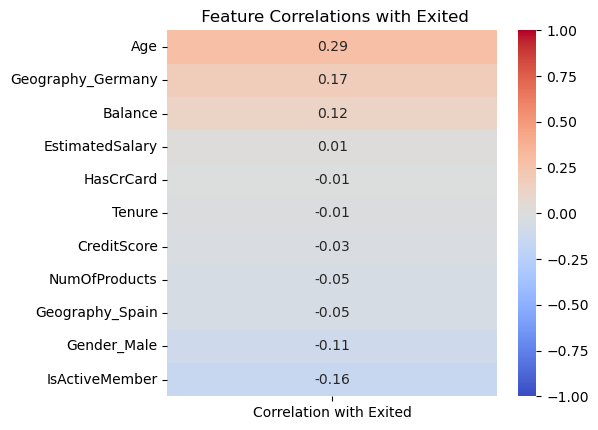

In [ ]:
# def corr_target(df):
#     if df.empty:
#         print("The DataFrame is empty.")
#         return None
#     correlation_matrixxx = df.corr()['Exited']
#     correlation_matrix = correlation_matrixxx.drop("Exited").sort_values(ascending=False)
#     return correlation_matrix
# corr = corr_target(df_encoded)
# print(corr)
# # corr.plot(kind='bar', x=corr.index, 
# #         y=corr.values,
# #         title='Correlation with Target Variable (Exited)',
# #         xlabel='Features', ylabel='Correlation Coefficient')
# # plt.show()
# plt.figure(figsize=(6, max(4, len(corr) * 0.4)))
# sns.heatmap(
#     corr.to_frame(name="Correlation with Exited"),
#     annot=True,
#     fmt=".2f",
#     cmap="coolwarm",
#     center=0,
#     vmin=-1,
#     vmax=1,
# )
# plt.title(" Feature Correlations with Exited")
# plt.tight_layout()
# plt.show()

In [17]:
def splitting_data(df):
    if df.empty:
        print("Dataframe is empty.")
        return None
    config = load_config()
    target = df['Exited']
    features = df.drop(columns=['Exited'], axis=1)
    x_temp,x_test, y_temp,y_test = train_test_split(features, target,
                                                    test_size=0.25, 
                                                    random_state=42,
                                                    stratify=target)
    x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp,
                                                      test_size=0.25, 
                                                      random_state=42,
                                                      stratify=y_temp)
    return x_train, x_val, x_test, y_train, y_val, y_test  
x_train, x_val, x_test, y_train, y_val, y_test = splitting_data(df_encoded)
print(f"Training set: {x_train.shape[0]} samples")
print(f"Validation set: {x_val.shape[0]} samples")


Training set: 5625 samples
Validation set: 1875 samples


In [18]:
print("The training columns are:", x_train.columns)
print("The minimum values in each column are:", [f"{value:.0f}" for value in x_train.min().values])
print("The maximum values in each column are:", [f"{value:.0f}" for value in x_train.max().values])
# print(x_train.head())

The training columns are: Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Geography_Germany',
       'Geography_Spain', 'Gender_Male'],
      dtype='object')
The minimum values in each column are: ['350', '18', '0', '0', '1', '0', '0', '12', '0', '0', '0']
The maximum values in each column are: ['850', '92', '10', '222268', '4', '1', '1', '199992', '1', '1', '1']


In [19]:
def scale_data():
    scaler = StandardScaler()
    scaler.fit(x_train)
    x_valid_scaled = scaler.transform(x_val)
    x_train_scaled = scaler.transform(x_train)  # Apply to training data
    x_test_scaled = scaler.transform(x_test)    # Apply same scaling to test data
    return x_train_scaled, x_valid_scaled, x_test_scaled

x_train, x_val, x_test = scale_data()

In [20]:
best_model = searches["Gradient Boosting"].best_estimator_

# Extract preprocessing and classifier
preprocessor = best_model.named_steps['preprocessing']
classifier = best_model.named_steps['classifier']

print(classifier)

GradientBoostingClassifier(learning_rate=0.2, n_estimators=50, random_state=42)


In [21]:
X_val_transformed = preprocessor.transform(x_val_raw)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrame
X_val_transformed = pd.DataFrame(
    X_val_transformed,
    columns=feature_names,
    index=x_val_raw.index
)

In [22]:
explainer = shap.TreeExplainer(classifier)

shap_values = explainer(X_val_transformed)

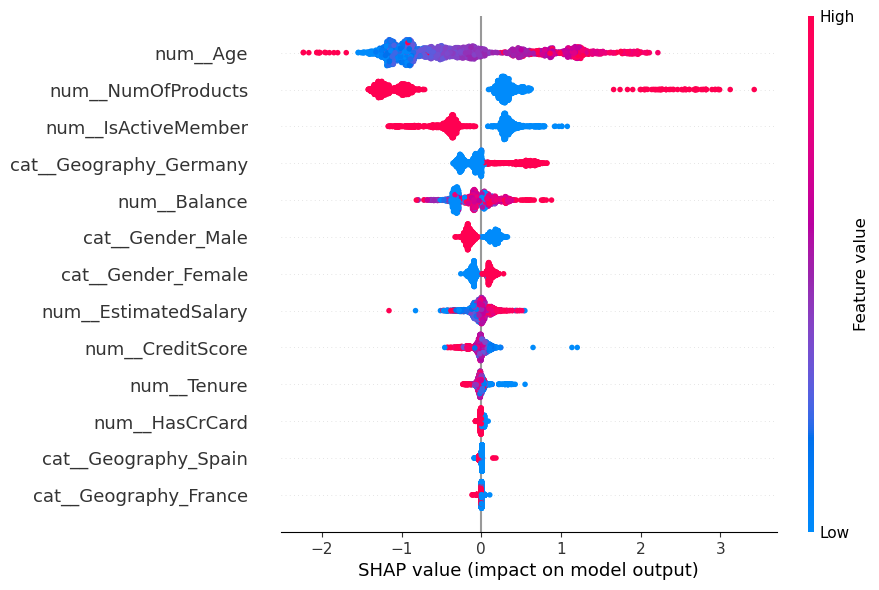

In [23]:
shap.plots.beeswarm(shap_values, max_display=15)

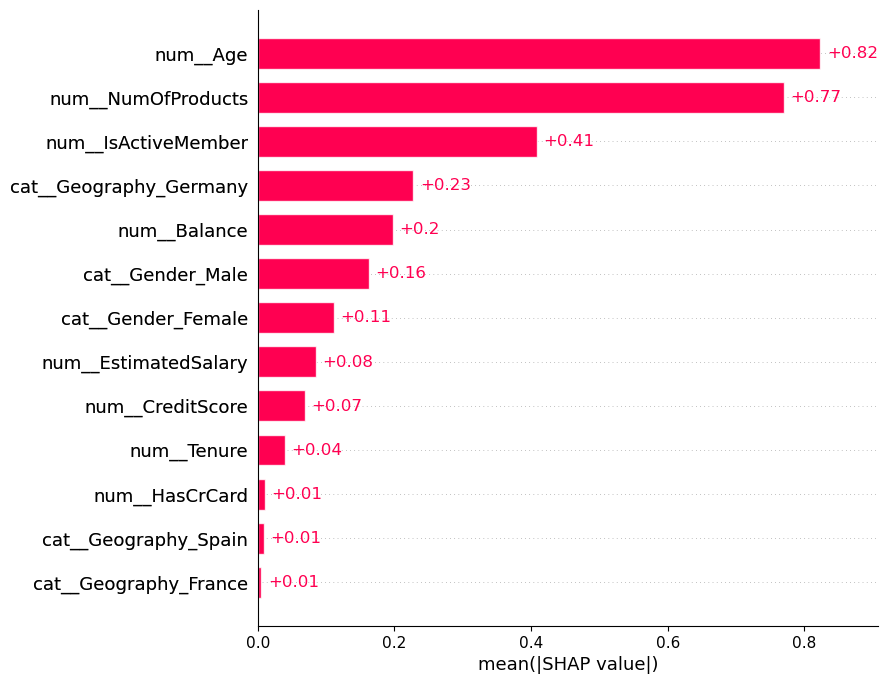

In [24]:
shap.plots.bar(shap_values, max_display=15)

The Gradient Boosting Classifier model is the best model based on the F1 score. The SHAP summary plot shows the top features contributing to the model's predictions, with their respective importance and impact on the target variable (Exited).

Conclusion

 The bank churn project developed a churn prediction model to help identify customers who are more likely to leave the bank. After removing non-informative identifiers and preparing the remaining customer data, we compared several models, including Logistic Regression, Gradient Boosting, and Random Forest. Because churn is a relatively rare event, we used F1 score as the main evaluation metric, along with class weighting and upsampling to improve detection of the minority class.

The final model selected was a class-weighted Random Forest, which performed best on the validation set with an F1 score of about 0.59. While this is promising, the model’s F1 score dropped to around 0.50 on the unseen test set, which means it is not yet strong enough for deployment without further refinement. In practical terms, the model can still help flag at-risk customers, but it should be treated as a decision-support tool rather than a final automated decision system.

The SHAP analysis shows that age, geography, account balance, and activity status are the most influential drivers of churn risk. Older customers and customers from Germany appear to be more likely to churn, while active membership is associated with lower churn risk. These insights are valuable for retention teams because they point to the customer segments that may need targeted interventions, such as loyalty offers, proactive outreach, or service improvements.

Recommendations

Collect a larger and more representative dataset, especially with more customers who churn.
Evaluate precision, recall, F1 score, and ROC AUC together, while continuing to use F1 score as the primary model-selection metric because the dataset is imbalanced. Accuracy should be treated as a supplementary metric rather than the main performance measure.Evaluate precision, recall, and F1 score together rather than relying on accuracy alone.
Use cross-validation and a separate, unseen test set for reliable performance estimates.
Monitor the model after deployment and retrain it regularly as customer behavior changes.